# Building an Image Dataset by Scraping

Every image dataset you have trained on so far arrived clean. This one will not. Here you pick
your own categories, search the web for them, and download whatever comes back — which is how
most real image datasets begin, and why most of the work in an image project happens before any
model is trained.

This notebook is your starting point for P2 Notebook 1. It demonstrates the provided scraper on
a small example. Your job is to replace the example with your own classes, scrape at full scale,
and justify your choices. The download-integrity check, the accounting table, and the manifest are
built in — run them and read what they tell you.

## Learning objectives

- Choose image classes that make a learnable, non-trivial classification problem
- Write several search queries per class and explain why one query is not enough
- Run a scraper with arguments you can justify, rather than defaults you inherited
- Account for the gap between images requested, images downloaded, and images readable
- Export a manifest that records what you actually trained on

## Background

You need to be comfortable with paths and folders (`pathlib`), with opening images in PIL, and
with building a DataFrame from a list of dictionaries. The scraping mechanics themselves are
handled for you by `ddgs_scraper.py`, which sits next to this notebook — you are expected to read
that module before you run it, because this assignment asks you to justify the arguments you pass.

Scraped images are copyrighted by whoever made them. They are fine to use for coursework, but do
**not** redistribute them, do **not** commit any of them to your repo, and do **not** publish your
dataset. They live in your local class data folder, outside the repo.

## This notebook covers

1. What the scraper does
2. Declaring your classes and queries
3. Running the scraper
4. Accounting for what came back
5. A first look at the images
6. Turning the records into a manifest

**Prerequisites:** none — this is the first notebook of P2.

**Dataset:** yours. Built here from Bing image search, via the `ddgs` package.

**References:** <https://pypi.org/project/ddgs/>

In [6]:
%pip install ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 29.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ddgs]1/2 [ddgs]
Note: you may need to restart the kernel to use updated packages.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

# The scraper lives in ddgs_scraper.py, in this same folder. Keep the two files
# together — if you move this notebook into your repo, move the module with it.
import ddgs_scraper

## 1. What the scraper does

`ddgs_scraper.py` wraps the `ddgs` package, which queries web image search. By default it asks Bing
Images directly — the same index DuckDuckGo Images draws its results from — because that is the
backend that works reliably (see `backend` in section 3). The pieces you will actually call are:

| Function | What it does |
|---|---|
| `search_images(query, ...)` | One search, paged until it has enough results. Returns raw result records — image URL, page URL, title, reported size |
| `download_image(url, ...)` | Fetches one URL and returns an RGB PIL image, or `None` if it isn't one |
| `passes_image_filters(img, ...)` | Checks a downloaded image against size and aspect-ratio limits |
| `scrape_class(label, queries, ...)` | All queries for one class, into one folder |
| `build_image_dataset(class_queries, ...)` | Every class. **This is the one you call.** |

Two things the scraper deliberately does *not* do, because they are your job in Notebook 2:
it does not check for duplicate images, and it does not judge whether the picture is actually of
the thing you searched for.

Read the module before running it. The arguments below are not magic numbers and you will be asked
to defend them.

In [14]:
# The filters every downloaded image has to pass. Both are measured on the image
# that actually arrived, not on the size the search engine claimed.
help(ddgs_scraper.build_image_dataset)

Help on function build_image_dataset in module ddgs_scraper:

build_image_dataset(
    class_queries: dict,
    save_dir: str | pathlib._local.Path,
    images_per_class: int = 250,
    results_per_query: int = 200,
    aspect_ratio_range: tuple = (0.5, 2.0),
    min_resolution: tuple = (200, 200),
    per_image_timeout: int = 10,
    backend: str = 'bing',
    safesearch: str = 'moderate',
    region: str = 'us-en',
    require_query_match: bool = True,
    query_delay: tuple = (2.0, 5.0),
    continue_on_error: bool = True,
    verbose: bool = True
) -> tuple[list[dict], dict]
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turn

## 2. Declaring your classes and queries

### 2.1 Choosing classes

Your categories are your choice, within the constraints in the assignment prompt: 3–10 classes, at
least 200 usable images each *after* cleaning, not a standard benchmark, and visually
distinguishable but not trivially so.

The last one is the constraint people get wrong. Classes a model separates at 99% teach you
nothing, and classes that are genuinely ambiguous teach you nothing either. Aim for categories a
person could sort reliably but not instantly — different hand tools, dog breeds, architectural
styles, cloud types, guitar body shapes.

### 2.2 Why several queries per class

A single search returns a narrow, repetitive slice of a category. Search "hammer" and you get a
thousand near-identical product photos of claw hammers on white backgrounds. Your model will learn
"white background" and fall over on the first photo taken in a garage.

Several queries per class widen what the class looks like, and they are also the main reason a
class survives deduplication with enough images left. The scraper uses every query: it searches
them all, then takes turns between them when downloading — first result of each query, then the
second of each — so each query supplies a roughly equal share of the class. If one query runs dry,
the others make up the difference. The run log reports how many images came from each query;
the `query` column of the manifest records it per image.


### Class Selection and Justification

This project focuses on recognizing five common protein sources from food images: chicken, salmon, beef, shrimp, and tofu.

The goal is to explore how computer vision can identify foods from photographs, potentially supporting future applications in nutrition tracking.

We selected these classes because:

- **Dataset size:** Five classes provide enough variety for meaningful model evaluation while keeping data collection manageable. We collected 350 images per class, exceeding the minimum target of 200 usable images after cleaning.
- **Custom dataset:** Images were collected through web scraping rather than using an existing benchmark dataset.
- **Visual differences:** The classes have recognizable differences in color, texture, and shape.
- **Classification difficulty:** Different cooking methods, seasonings, lighting conditions, and presentations make the task challenging without being overly ambiguous.

### Expected Model Confusion

Before training, we predict that **chicken and tofu will be the most frequently confused classes**, especially when both are browned, cubed, or heavily seasoned.

We will test this prediction against the confusion matrices in Notebook 3.


In [15]:

CLASS_QUERIES = {
    "chicken": [
        "grilled chicken breast",
        "roasted chicken breast",
        "sliced cooked chicken"
    ],
    "salmon": [
        "baked salmon fillet",
        "grilled salmon",
        "pan seared salmon"
    ],
    "beef": [
        "grilled beef steak",
        "sliced cooked steak",
        "beef sirloin steak"
    ],
    "shrimp": [
        "grilled shrimp",
        "cooked shrimp",
        "sauteed shrimp"
    ],
    "tofu": [
        "crispy tofu cubes",
        "pan fried tofu",
        "baked tofu"
    ]
}

for label, queries in CLASS_QUERIES.items():
    print(f"{label:<20} {len(queries)} queries")


chicken              3 queries
salmon               3 queries
beef                 3 queries
shrimp               3 queries
tofu                 3 queries


## 3. Running the scraper

The settings below are small on purpose — this is a demonstration run that should finish in a
minute or two. **For your actual dataset you will need much larger numbers.**

A rough guide: to end up with 200 usable images per class after Notebook 2's cleaning, plan to
save 300–400 per class here. You will lose images to wrong subjects, duplicates, and files that
turn out not to open.

Each argument is a decision you have to justify in your writeup:

- `save_dir` — where the images go: your local class data folder, **never** inside your repo. Only the manifest is committed
- `images_per_class` — how many you keep. Set it above your target, not at it
- `results_per_query` — how many search results to collect, fetched a page at a time. Most will not survive download and filtering
- `min_resolution` — a floor on quality. Small images look terrible resized up to 224×224
- `aspect_ratio_range` — rejects banners and infographics, which are rarely pictures of your subject
- `per_image_timeout` — seconds allowed for one download, start to finish. Each image gets one attempt; a slow or dead host is skipped, not retried
- `backend` — which search engine `ddgs` asks. `'bing'` is the reliable one. DuckDuckGo's image results come from Bing anyway, and the `'duckduckgo'` backend currently fails on every request
- `safesearch` — leave it at `'moderate'`. Note that the `'bing'` backend ignores it and always applies Bing's default, which is Moderate
- `region` — changes what you get back. Say so if you change it. Also ignored by `'bing'`
- `require_query_match` — drops results that never mention your query (section 3.2). Leave it on unless your query's words genuinely do not appear in image titles

### 3.1 Expect to be rate limited

Search engines throttle scrapers, and when they do the `ddgs` package reports **"No results
found"** rather than an explicit rate-limit error. That looks identical to a query that genuinely
matched nothing.

The scraper retries a few times with backoff before believing it, and marks any class that ends
with zero images as `empty` in the summary rather than `ok`. You still need to watch for it:

- A class reported as `empty`, or with far fewer images than its neighbours, is almost always
  throttling — not a bad query
- The fix is to wait several minutes and re-run **just that class**. Images already saved stay put,
  but note that filenames restart at `_0000`, so scrape a class into a clean folder or renumber
- Scraping five classes at full scale in one uninterrupted run is unlikely to work. Plan to do it
  in batches over more than one sitting
- This is the single most common reason a class comes up short of 200. Start early

### 3.2 Watch for results from someone else's search

Occasionally the search engine answers with a page of results for a different query entirely — a
search for "acoustic guitar" once came back as 35 stills from a 1991 movie. Those images download
fine and pass every size filter, so nothing downstream would stop them landing in your class folder.

The scraper checks every page it gets back. A result whose title, page URL, and image URL never
mention a word of your query is dropped, and a page where fewer than half the results mention it is
treated as a bad response and retried, the same way an empty page is.

This is a guard against garbage, **not** a label check: an electric guitar titled "guitar" still
passes a query for "acoustic guitar". Catching those is what section 5 and Notebook 2 are for.

In [19]:

from pathlib import Path

# Save images outside the GitHub repository
IMAGE_DIR = Path.home() / "MSDS565_data" / "P2_images"

# Start with a small test before collecting the full dataset
IMAGES_PER_CLASS = 350

records, summary = ddgs_scraper.build_image_dataset(
    class_queries=CLASS_QUERIES,
    save_dir=IMAGE_DIR,
    images_per_class=IMAGES_PER_CLASS,
    results_per_query=200,
    aspect_ratio_range=(0.5, 2.0),
    min_resolution=(200, 200),
    per_image_timeout=10,
    backend="bing",
    safesearch="moderate",
    region="us-en",
    require_query_match=True,
)



[1/5] class 'chicken' — 3 queries
  query 1/3: 'grilled chicken breast'
    200 results returned
  query 2/3: 'roasted chicken breast'
    200 results returned
  query 3/3: 'sliced cooked chicken'
    200 results returned
  downloading from 600 results, taking turns between queries
    ...tried 10, class has 10/350
    ...tried 20, class has 20/350
    ...tried 30, class has 29/350
    ...tried 40, class has 39/350
    ...tried 50, class has 49/350
    ...tried 60, class has 59/350
    ...tried 70, class has 69/350
    ...tried 80, class has 79/350
    ...tried 90, class has 89/350
    ...tried 100, class has 99/350
    ...tried 110, class has 109/350
    ...tried 120, class has 119/350
    ...tried 130, class has 129/350
    ...tried 140, class has 139/350
    ...tried 150, class has 149/350
    ...tried 160, class has 159/350
    ...tried 170, class has 169/350
    ...tried 180, class has 179/350
    ...tried 190, class has 189/350
    ...tried 200, class has 199/350
    ...tried 21

In [12]:
from PIL import Image
from pathlib import Path

unreadable = []

for label in summary["classes"]:
    class_dir = Path(summary["save_dir"]) / label

    for path in sorted(class_dir.glob("*.jpg")):
        try:
            with Image.open(path) as img:
                img.verify()
        except (OSError, ValueError) as e:
            unreadable.append((label, path.name, str(e)))
            path.unlink()

print(f"{len(unreadable)} unreadable images removed.")

0 unreadable images removed.



### Scraping Configuration and Justification

We configured the scraper to collect 350 images per class across five protein sources, targeting 1,750 images total. This provides a buffer above the required 200 usable images per class, since duplicates, irrelevant images, and low-quality results will be removed during cleaning.

The scraper used the following settings:

- **Results per query (200):** Collects a broad range of search results across three queries per class, helping capture different cooking methods and presentations.
- **Minimum resolution (200 × 200):** Filters out small images that could lose important visual details when resized.
- **Aspect ratio (0.5–2.0):** Removes extremely narrow or wide images while preserving different food photography compositions.
- **Download timeout (10 seconds):** Prevents unresponsive websites from slowing down the scraping process excessively.
- **Search backend (Bing):** Uses the scraper's recommended backend for reliable image retrieval.
- **SafeSearch (Moderate):** Uses the default content filtering. The Bing backend applies its own Moderate filtering.
- **Query matching (True):** Filters results that do not mention relevant search terms, reducing unrelated downloads.
- **Region (us-en):** Uses the default region setting, although the Bing backend does not apply this parameter.
- **Query delay (2–5 seconds):** Introduces pauses between searches to reduce the likelihood of rate limiting.

Three search queries were used per protein source to capture variation in cooking methods, appearance, and presentation. The final download produced 350 readable images per class, with no corrupted files detected during validation.


## 4. Accounting for what came back

The assignment tracks each class from **requested** through **downloaded** to **readable**. This
section does that for you: 4.1 checks that every saved file actually opens, and 4.2 builds the
table and flags any class at risk of ending up short. Your job is to read the result — a count you
cannot explain is the problem the prompt is warning about, not the fact that images were lost.

### 4.1 Download integrity

Some downloads arrive truncated, empty, or as a different format wearing the wrong extension. The
scraper only saves images it managed to decode, so everything on disk *should* open — this pass
checks instead of assuming. It opens every saved file with PIL inside a `try`/`except`, the same
pattern `U2-2_CNN-8_Explainability` §1 uses, then logs and deletes any file that fails.

`load()` is what does the checking. `Image.open` only reads the file's header; a truncated file
fails only when its pixels are actually decoded.

In [20]:
from PIL import Image

# Open and fully decode every saved image. Anything PIL cannot read is logged and
# deleted, so Notebook 2 never trips over it.
unreadable = []          # one (label, filename, error) entry per file that failed

for label in summary['classes']:
    for path in sorted(Path(summary['save_dir'], label).glob('*.jpg')):
        try:
            with Image.open(path) as img:
                img.load()       # full decode — this is what catches a truncated file
        except Exception as e:
            unreadable.append((label, path.name, f'{type(e).__name__}: {e}'))
            path.unlink()        # delete the unreadable file

print(f'{len(unreadable)} unreadable files found and deleted')
for label, name, error in unreadable:
    print(f'  {label}/{name} -> {error}')

0 unreadable files found and deleted


### 4.2 Raw accounting

One row per class: **requested** is the `IMAGES_PER_CLASS` you asked the scraper for,
**downloaded** is what it saved, **unreadable** is what 4.1 deleted, and **readable** is what is
left.

A class is flagged **at risk** when it has fewer than 300 readable images. Notebook 2's cleaning
removes wrong subjects and duplicates, and a class that starts below about 300 rarely keeps the 200
the assignment requires. At this demo scale every class is flagged — that is expected. At full
scale, re-scrape any flagged class **now**, not after Notebook 2.

In [21]:
# A class needs about this many readable images now to keep 200 after Notebook 2's cleaning
MIN_READABLE = 300

rows = []
for label, info in summary['classes'].items():
    n_unreadable = sum(1 for lbl, name, error in unreadable if lbl == label)
    n_readable = info['saved'] - n_unreadable
    rows.append({
        'class': label,
        'queries': info['queries'],
        'requested': IMAGES_PER_CLASS,
        'downloaded': info['saved'],
        'unreadable': n_unreadable,
        'readable': n_readable,
        'status': info['status'],
        'at_risk': n_readable < MIN_READABLE,
    })

counts = pd.DataFrame(rows)

print(f"Output folder: {summary['save_dir']}")
counts

Output folder: /Users/timhamilton/MSDS565_data/P2_images


,class,queries,requested,downloaded,unreadable,readable,status,at_risk
0,chicken,3,350,350,0,350,ok,False
1,salmon,3,350,350,0,350,ok,False
2,beef,3,350,350,0,350,ok,False
3,shrimp,3,350,350,0,350,ok,False
4,tofu,3,350,350,0,350,ok,False


## 5. A first look at the images

Before anything else, look at what you actually downloaded. This is the fastest way to discover
that a query returned drawings, product collages, or pictures of the *word* rather than the thing.

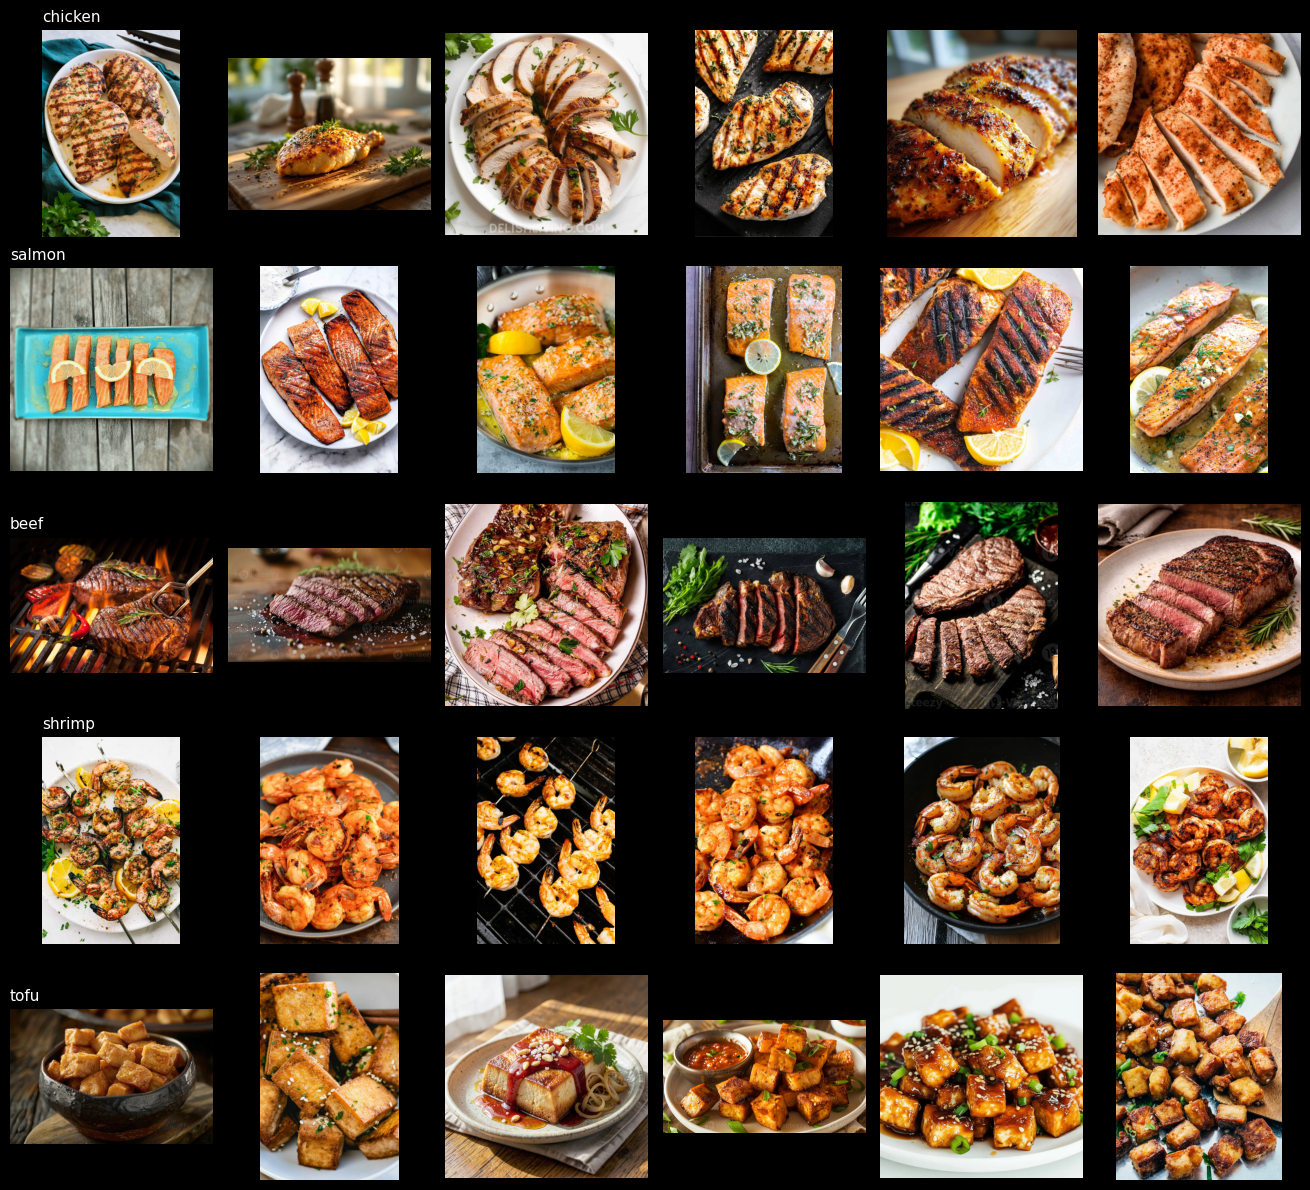

In [18]:
n_show = 6
labels = list(summary['classes'].keys())

fig, axes = plt.subplots(len(labels), n_show, figsize=(2.2 * n_show, 2.4 * len(labels)))
axes = np.atleast_2d(axes)

for r, label in enumerate(labels):
    files = sorted(Path(summary['save_dir'], label).glob('*.jpg'))[:n_show]
    for c in range(n_show):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(files):
            ax.imshow(Image.open(files[c]))
            if c == 0:
                ax.set_title(label, loc='left', fontsize=11)

plt.tight_layout()
plt.show()

## 6. Turning the records into a manifest

`records` is one row per saved image. The manifest is the permanent record of what you trained on,
and it matters more here than in a normal project: **search results change over time, so re-running
this scraper later will not give you the same dataset.** The manifest is the only reproducible
account of the run.

The prompt requires at minimum `filename`, `label`, `source_url`, `query`, and a boolean
`readable`. The scraper supplies everything but `readable`, which comes from the integrity pass in
section 4.1.

Notebook 2 extends this file with a `kept` column. Add to it there; do not overwrite it.

In [22]:
manifest = pd.DataFrame(records)

# readable comes from the integrity pass in 4.1: False for every file it deleted
unreadable_names = [name for label, name, error in unreadable]
manifest['readable'] = ~manifest['filename'].isin(unreadable_names)

Path('data').mkdir(exist_ok=True)
manifest.to_csv('data/P2_manifest.csv', index=False)

print(f'{len(manifest)} rows written to data/P2_manifest.csv')
manifest.head()

1750 rows written to data/P2_manifest.csv


,filename,label,query,image_url,source_url,title,width,height,readable
0,chicken_0000.jpg,chicken,grilled chicken breast,https://recipesbylucelle.com/wp-content/upload...,https://recipesbylucelle.com/grilled-chicken-b...,Perfect Grilled Chicken Breast Recipe - Recipe...,1024,1024,True
1,chicken_0001.jpg,chicken,roasted chicken breast,https://diethood.com/wp-content/uploads/2018/1...,https://diethood.com/oven-baked-chicken-breasts/,Oven Roasted Chicken Breast,1200,1800,True
2,chicken_0002.jpg,chicken,sliced cooked chicken,https://delishliving.com/wp-content/uploads/20...,https://delishliving.com/thin-sliced-chicken-b...,Delicious Thin Sliced Chicken Breast Recipe - ...,1200,1200,True
3,chicken_0003.jpg,chicken,grilled chicken breast,https://www.eatingbirdfood.com/wp-content/uplo...,https://nordicrecipebox.com/grilled-chicken-br...,Grilled Chicken Breast Recipes,1200,1670,True
4,chicken_0004.jpg,chicken,roasted chicken breast,https://www.cookingclassy.com/wp-content/uploa...,https://www.cookingclassy.com/baked-chicken-br...,Baked Chicken Breast (Easy Flavorful Recipe) -...,1200,1800,True


## Review

This notebook built a small labeled image dataset from scratch:

1. **The scraper** (`ddgs_scraper.py`) searches for images, downloads results, filters by size and
   aspect ratio, and saves one folder per class
2. **Classes and queries** are declared as a dictionary — several queries per class, because one
   query returns one narrow slice of a category
3. **Running it** produced both the images on disk and a record per image
4. **Integrity and accounting** opened every saved file, tracked each class requested →
   downloaded → readable, and flagged any class at risk of ending up short
5. **Looking at the images** is the fastest way to catch a query that returned the wrong thing
6. **The manifest** is the reproducible record of a scrape that cannot be reproduced by re-running

### To turn this into your P2 Notebook 1

- [ ] Replace `CLASS_QUERIES` with your own 3–10 classes, and justify each in a markdown cell:
      why these, what makes them separable, where you expect the model to struggle
- [ ] State, before you model anything, which **pair of classes you expect to be confused most**.
      Notebook 3 will check you
- [ ] Justify every argument you pass to `build_image_dataset`
- [ ] Scrape at full scale — aim to save 300–400 per class to land 200 after cleaning
- [ ] Re-scrape any class the accounting table flags as at risk — **now**, not after Notebook 2

**Next:** `P2_Images-2_Preprocessing_<TeamName>.ipynb` turns this folder of search results into
an actual dataset.